In [1]:
%%writefile /kaggle/working/03_preprocess_mri.py
import os, time
import numpy as np
import pandas as pd
import pydicom
import cv2
from concurrent.futures import ProcessPoolExecutor, as_completed
from tqdm.auto import tqdm

BASE    = "/kaggle/input/competitions/rsna-knee-abnormality-detection"
SPLIT   = "train"                     # "train" atau "test"
OUT_DIR = f"/kaggle/working/vol_{SPLIT}"
IMG     = 224                         # ukuran in-plane
DEPTH   = 16                          # jumlah slice per view
LIMIT   = None                        # None = semua studi
VIEWS   = ["Sagittal", "Coronal", "Axial"]


def choose_series(g, series_root):
    """Pilih satu series per plane: utamakan fluid-sensitive + fat-sat,
    lalu yang slice-nya paling banyak."""
    chosen = {}
    for p in VIEWS:
        c = g[g["Anatomical_Plane"] == p].copy()
        if c.empty:
            chosen[p] = None
            continue
        c["score"] = c["Fluid_Sensitive"] * 2 + c["Fat_Suppression"]
        c["n"] = [len(os.listdir(os.path.join(series_root, s)))
                  if os.path.isdir(os.path.join(series_root, s)) else 0
                  for s in c["SeriesInstanceUID"]]
        c = c[c["n"] > 0].sort_values(["score", "n"], ascending=False)
        chosen[p] = c["SeriesInstanceUID"].iloc[0] if len(c) else None
    return chosen


def load_series(path):
    """Baca semua slice DICOM dan urutkan secara spasial (bukan nama file)."""
    slices = []
    for f in os.listdir(path):
        if not f.endswith(".dcm"):
            continue
        ds = pydicom.dcmread(os.path.join(path, f))
        try:
            pos = np.array(ds.ImagePositionPatient, dtype=float)
            ori = np.array(ds.ImageOrientationPatient, dtype=float)
            key = float(pos @ np.cross(ori[:3], ori[3:]))
        except Exception:
            key = float(getattr(ds, "InstanceNumber", 0))
        img = ds.pixel_array.astype(np.float32)
        if getattr(ds, "PhotometricInterpretation", "") == "MONOCHROME1":
            img = img.max() - img
        slices.append((key, img))
    slices.sort(key=lambda x: x[0])
    return [s[1] for s in slices]


def square_resize(img, size):
    """Pad ke persegi (tanpa distorsi rasio), lalu resize."""
    h, w = img.shape
    m = max(h, w)
    canvas = np.zeros((m, m), np.float32)
    y, x = (m - h) // 2, (m - w) // 2
    canvas[y:y + h, x:x + w] = img
    return cv2.resize(canvas, (size, size), interpolation=cv2.INTER_AREA)


def to_volume(slices):
    vol = np.stack([square_resize(s, IMG) for s in slices])        # (N, IMG, IMG)
    fg = vol[vol > 0]
    lo, hi = np.percentile(fg if fg.size else vol, [0.5, 99.5])     # normalisasi per volume
    vol = np.clip((vol - lo) / (hi - lo + 1e-6), 0, 1)
    idx = np.linspace(0, len(vol) - 1, DEPTH).round().astype(int)   # resample ke DEPTH slice
    return (vol[idx] * 255).astype(np.uint8)


def process_study(study_uid, g):
    series_root = os.path.join(BASE, f"{SPLIT}_series", study_uid)
    chosen = choose_series(g, series_root)
    vol = np.zeros((len(VIEWS), DEPTH, IMG, IMG), np.uint8)
    mask = np.zeros(len(VIEWS), np.uint8)
    meta = []
    for i, p in enumerate(VIEWS):
        s_uid, n, err = chosen[p], 0, ""
        if s_uid is not None:
            try:
                slices = load_series(os.path.join(series_root, s_uid))
                n = len(slices)
                if n:
                    vol[i] = to_volume(slices)
                    mask[i] = 1
            except Exception as e:
                err = f"{type(e).__name__}: {str(e)[:120]}"
        meta.append({"StudyInstanceUID": study_uid, "view": p, "SeriesInstanceUID": s_uid,
                     "n_slices": n, "ok": int(mask[i]), "error": err})
    np.savez_compressed(os.path.join(OUT_DIR, f"{study_uid}.npz"), vol=vol, mask=mask)
    return meta


def main():
    os.makedirs(OUT_DIR, exist_ok=True)
    series = pd.read_csv(os.path.join(BASE, f"{SPLIT}_series.csv"))
    groups = dict(tuple(series.groupby("StudyInstanceUID")))
    studies = sorted(groups)
    studies = [s for s in studies
               if not os.path.exists(os.path.join(OUT_DIR, f"{s}.npz"))]   # bisa di-resume
    if LIMIT:
        studies = studies[:LIMIT]
    print(f"Diproses: {len(studies)} studi, CPU: {os.cpu_count()}")

    t0, rows = time.time(), []
    with ProcessPoolExecutor(max_workers=os.cpu_count()) as ex:
        futs = [ex.submit(process_study, s, groups[s]) for s in studies]
        for f in tqdm(as_completed(futs), total=len(futs)):
            rows.extend(f.result())

    meta_path = os.path.join(OUT_DIR, "_meta.csv")
    meta = pd.DataFrame(rows)
    if os.path.exists(meta_path):
        meta = pd.concat([pd.read_csv(meta_path), meta], ignore_index=True)
    meta.to_csv(meta_path, index=False)

    dt = time.time() - t0
    print(f"\nSelesai {len(studies)} studi dalam {dt/60:.1f} menit "
          f"({dt/max(len(studies),1):.2f} detik/studi)")
    print("View tersedia (%):")
    print((meta.groupby("view")["ok"].mean() * 100).round(1).to_string())
    print("Jumlah error:", (meta["error"].fillna("") != "").sum())
    errs = meta.loc[meta["error"].fillna("") != "", "error"]
    if len(errs):
        print(errs.value_counts().head(5).to_string())
    size = sum(os.path.getsize(os.path.join(OUT_DIR, f)) for f in os.listdir(OUT_DIR))
    print(f"Ukuran folder output: {size/1e9:.2f} GB")


if __name__ == "__main__":
    main()

Writing /kaggle/working/03_preprocess_mri.py


In [2]:
!python /kaggle/working/03_preprocess_mri.py

Diproses: 4407 studi, CPU: 4
100%|███████████████████████████████████████| 4407/4407 [45:11<00:00,  1.63it/s]

Selesai 4407 studi dalam 45.2 menit (0.62 detik/studi)
View tersedia (%):
view
Axial       100.0
Coronal     100.0
Sagittal    100.0
Jumlah error: 0
Ukuran folder output: 6.76 GB


(3, 16, 224, 224) [1 1 1]


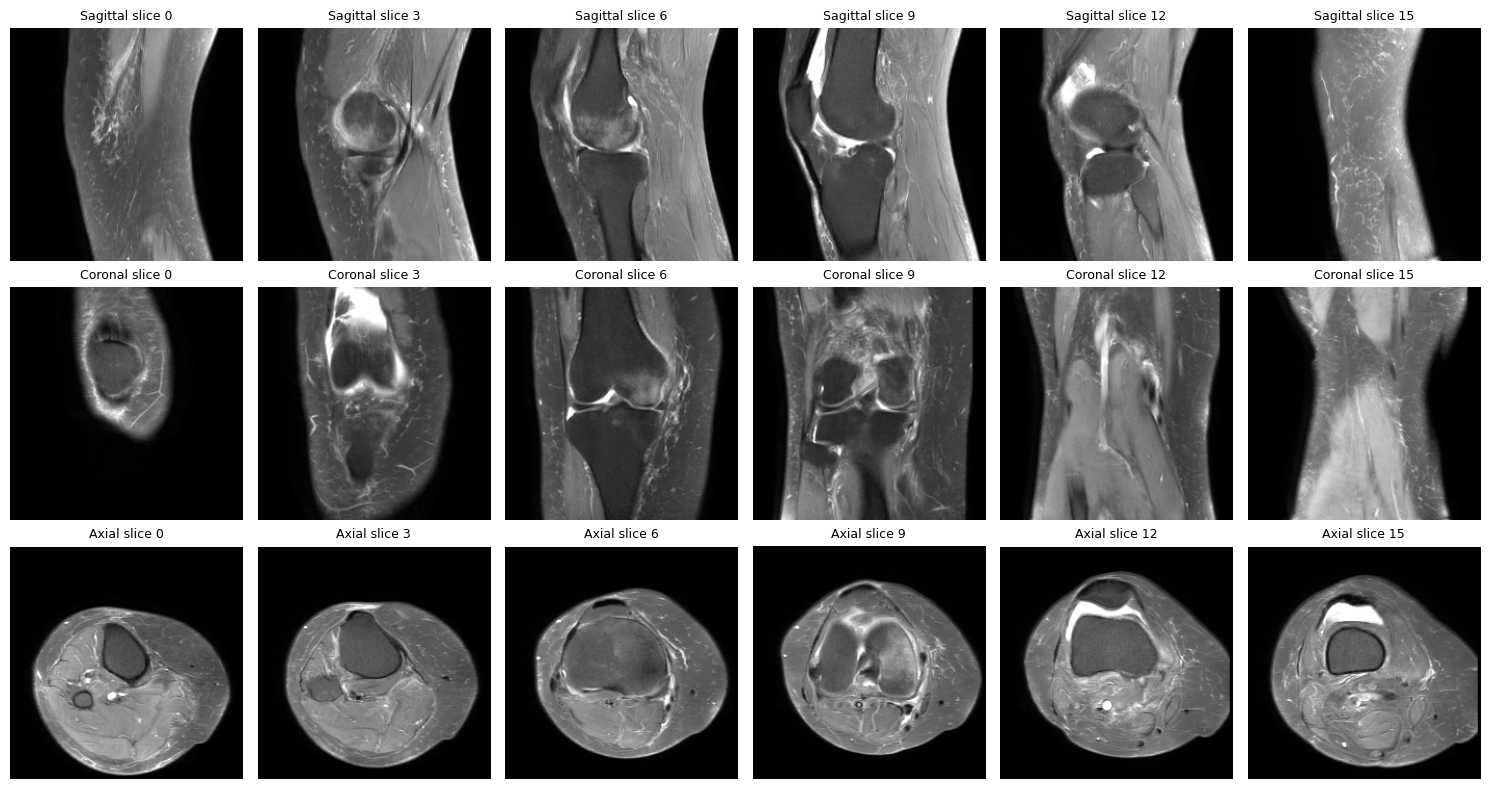

In [3]:
import glob, numpy as np, matplotlib.pyplot as plt
f = sorted(glob.glob("/kaggle/working/vol_train/*.npz"))[0]
d = np.load(f); vol, mask = d["vol"], d["mask"]
print(vol.shape, mask)

fig, ax = plt.subplots(3, 6, figsize=(15, 8))
for i, name in enumerate(["Sagittal", "Coronal", "Axial"]):
    for j, s in enumerate(np.linspace(0, vol.shape[1] - 1, 6).astype(int)):
        ax[i, j].imshow(vol[i, s], cmap="gray")
        ax[i, j].set_title(f"{name} slice {s}", fontsize=9)
        ax[i, j].axis("off")
plt.tight_layout(); plt.show()